Comparative Intelligence and Ethics in Machine Learning Systems

Fashion-MNIST: HOG + Linear SVM vs Convolutional Neural Network

Application track: Computer Vision — multiclass image classification

Dataset: Fashion-MNIST

Primary comparison: engineered visual features with a classical classifier versus end-to-end learned convolutional features

Research question

How does a classical machine-learning approach based on engineered visual features compare with a convolutional neural network in terms of classification performance, generalisation, explainability, robustness and suitability for real-world fashion image classification?

This notebook follows a controlled comparison. Both approaches use the same Fashion-MNIST training/test observations, the same five stratified validation folds, and the same final held-out test set. The analysis covers the assignment requirements for preprocessing, model design, performance metrics, robust validation, explainability, bias/diagnostic analysis, ethics and deployment.

For ethical and deployment discussion, the models are treated as prototypes for an online marketplace that automatically assigns clothing images to catalogue categories.

1. Tools, reproducibility and experimental design

The implementation uses:

Tool -	Purpose -	Rationale

NumPy / Pandas -	numerical processing and result tables	lightweight - transparent analysis

Matplotlib -	plots and diagnostics -	consistent visual comparison

scikit-image -	HOG feature extraction -	established classical computer-vision descriptor

scikit-learn -	Linear SVM, metrics and stratified cross-validation	mature - classical ML/evaluation tooling

PyTorch / TorchVision -	CNN training and Fashion-MNIST loading -	explicit control over architecture and training

LIME -	model-agnostic local explanation of HOG + SVM -	suitable for explaining a non-probabilistic classical pipeline

Captum Integrated Gradients -	input attribution for the CNN -	gradient-based neural-network explanation


All stochastic operations use seed 123 where supported. Reproducibility can still vary slightly across hardware/backends, especially GPU kernels.

Test-set policy: the official 10,000-image test set is kept outside model/hyperparameter selection. It is used only after both model configurations are frozen.

In [ ]:
# Optional dependency installation if running in a fresh environment.
# Uncomment if required.
%pip install -q scikit-image scikit-learn torch torchvision lime captum

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import copy
from IPython.display import display

import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

from skimage.feature import hog
from skimage.segmentation import slic, mark_boundaries

from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from lime import lime_image
from scipy.special import softmax
from captum.attr import IntegratedGradients

# Fix random seeds so that weight initialisation, data shuffling and
# other stochastic operations are as reproducible as possible.
random.seed(123)
np.random.seed(123)
torch.manual_seed(123)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)

# Use hardware acceleration when available; otherwise fall back to CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 24.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 17.7 MB/s eta 0:00:00
Using device: cuda


2. Dataset selection and exploratory analysis

Fashion-MNIST was introduced by Xiao, Rasul and Vollgraf (2017) as a more challenging drop-in replacement for MNIST. It contains 70,000 grayscale 28×28 images from 10 fashion categories, split into 60,000 training and 10,000 test images, with 7,000 examples per class overall.

Why this dataset?

Fashion-MNIST is appropriate for the comparison because:
- the fixed image size and balanced classes support a controlled classical-ML vs DL experiment;
- visually similar classes such as Shirt, T-shirt/top, Pullover and Coat provide meaningful error-analysis cases;
- its modest size makes repeated five-fold validation computationally feasible;
- the absence of personal photographs reduces direct privacy risk in the benchmark itself, while still allowing discussion of how privacy changes in a real deployment.

Source: Xiao, H., Rasul, K. and Vollgraf, R. (2017), Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms. Original dataset repository: https://github.com/zalandoresearch/fashion-mnist

In [2]:
transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples:     {len(test_dataset)}")

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Numeric label:", label)
print("Class name:", class_names[label])


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 172kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.0MB/s]

Training samples: 60000
Test samples:     10000
Image shape: torch.Size([1, 28, 28])
Label: 9
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Numeric label: 9
Class name: Ankle boot


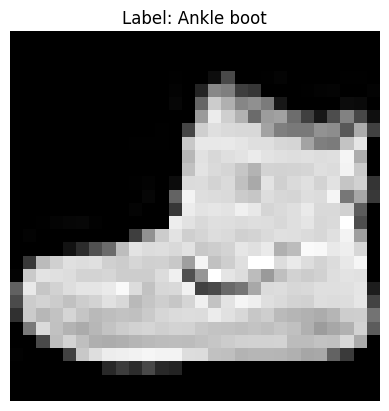

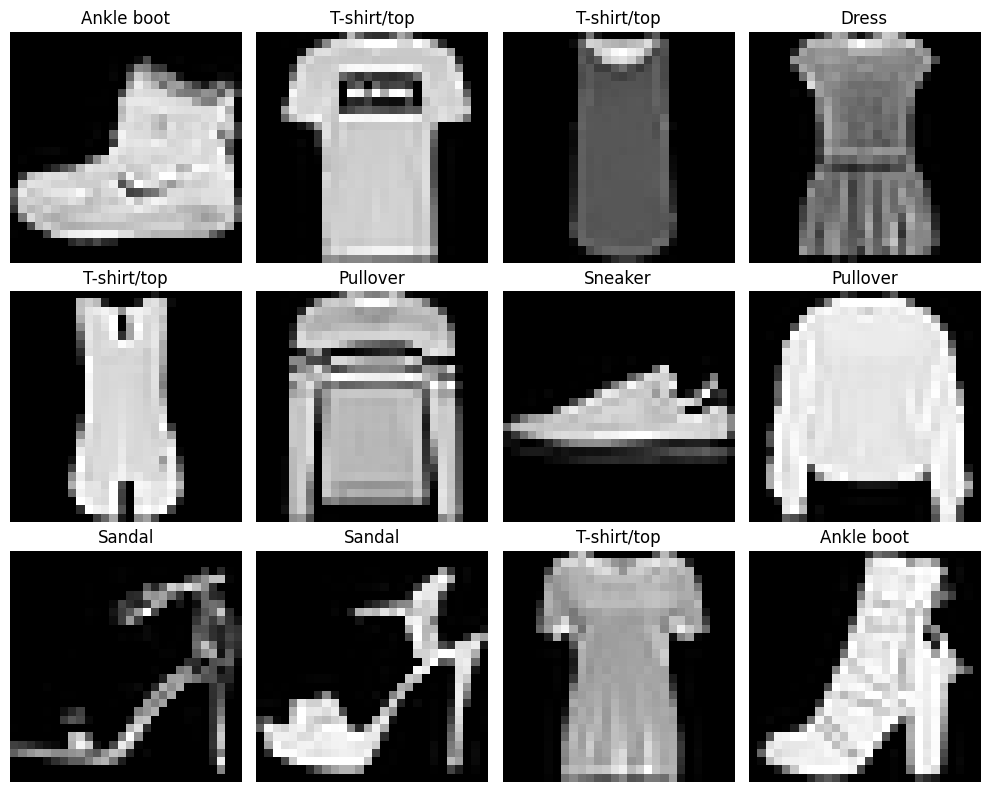

In [3]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {class_names[label]}")
plt.axis("off")
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

,Class ID,Class Name,Count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


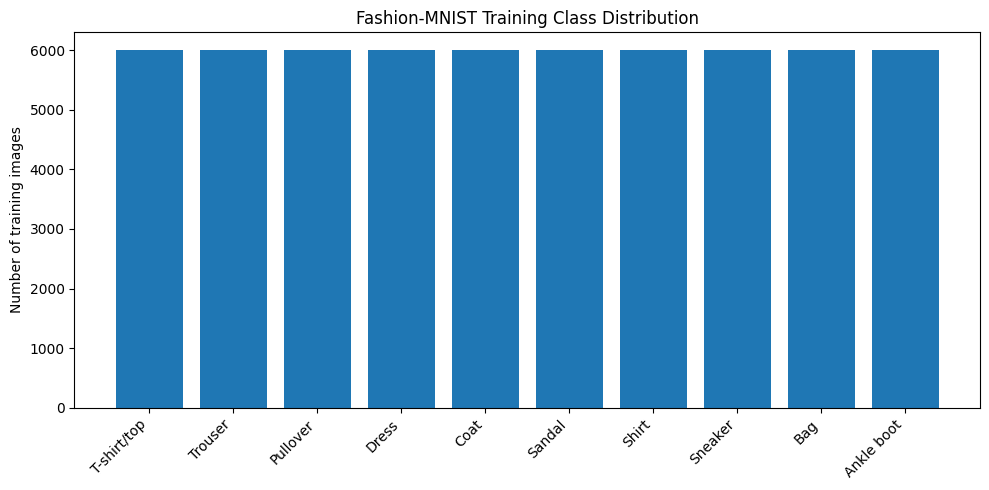

In [4]:
targets = train_dataset.targets.numpy()

unique_classes, counts = np.unique(targets, return_counts=True)

class_distribution = pd.DataFrame({
    "Class ID": unique_classes,
    "Class Name": [class_names[i] for i in unique_classes],
    "Count": counts
})

display(class_distribution)

plt.figure(figsize=(10, 5))

plt.bar(
    class_distribution["Class Name"],
    class_distribution["Count"]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of training images")
plt.title("Fashion-MNIST Training Class Distribution")

plt.tight_layout()
plt.show()


In [5]:
all_images = train_dataset.data.float() / 255.0

print("Dataset shape:", all_images.shape)
print("Mean pixel value:", all_images.mean().item())
print("Standard deviation:", all_images.std().item())

Dataset shape: torch.Size([60000, 28, 28])
Mean pixel value: 0.2860405743122101
Standard deviation: 0.3530242443084717


Dataset observations

The training split is perfectly balanced at 6,000 images per class, so overall accuracy is not inflated by a majority class. Nevertheless, balanced labels do not imply that all classes are equally difficult or that the dataset is representative of real-world fashion.

The images are low-resolution, grayscale, centred and visually standardised. These characteristics make the benchmark controlled, but they later become important limitations when discussing deployment to real marketplace photography.

3. Validation strategy and evaluation metrics

The 60,000-image training split is used for stratified five-fold cross-validation. In each fold, 48,000 observations are used for training and 12,000 for validation. Stratification preserves the equal class distribution.

Five folds were chosen as a balance between robust estimation and the computational cost of repeatedly training the CNN. The official 10,000-image test set remains untouched until final evaluation.

The assignment-required metrics are:
- Accuracy: proportion of all predictions that are correct.
- Precision: among predictions assigned to a class, the proportion that are correct.
- Recall: among all true examples of a class, the proportion recovered.
- F1-score: harmonic mean of precision and recall.

Macro averaging is used for precision, recall and F1 so every clothing class contributes equally. Macro F1 is the main model-selection metric because it exposes weak performance on difficult classes rather than relying only on aggregate accuracy.

In [6]:
# Fashion-MNIST stores the class label for each training image as an integer from 0 to 9.
targets = train_dataset.targets.numpy()

print("Number of labels:", len(targets))
print("First 20 labels:", targets[:20])

# Five folds give us multiple independent validation results without making
# the computational cost excessive for the CNN later.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

# We only inspect the indices here; no model is being trained yet.
for fold, (train_idx, val_idx) in enumerate(
    cv.split(np.zeros(len(targets)), targets),
    start=1
):
    print(
        f"Fold {fold}: "
        f"{len(train_idx)} training samples, "
        f"{len(val_idx)} validation samples"
    )

    # Examine the first fold to confirm that every class is represented equally.
train_idx, val_idx = next(
    cv.split(np.zeros(len(targets)), targets)
)

val_labels = targets[val_idx]

unique_classes, val_counts = np.unique(
    val_labels,
    return_counts=True
)

for class_id, count in zip(unique_classes, val_counts):
    print(f"{class_names[class_id]:15s}: {count}")

Number of labels: 60000
First 20 labels: [9 0 0 3 0 2 7 2 5 5 0 9 5 5 7 9 1 0 6 4]
Fold 1: 48000 training samples, 12000 validation samples
Fold 2: 48000 training samples, 12000 validation samples
Fold 3: 48000 training samples, 12000 validation samples
Fold 4: 48000 training samples, 12000 validation samples
Fold 5: 48000 training samples, 12000 validation samples
T-shirt/top    : 1200
Trouser        : 1200
Pullover       : 1200
Dress          : 1200
Coat           : 1200
Sandal         : 1200
Shirt          : 1200
Sneaker        : 1200
Bag            : 1200
Ankle boot     : 1200


4. Classical machine learning: HOG + Linear SVM

4.1 HOG feature representation

Histogram of Oriented Gradients (HOG) converts each image into a hand-engineered descriptor based on local gradient directions (Dalal and Triggs, 2005). The configuration used here is:
- 9 orientations
- 4×4 pixels per cell
- 2×2 cells per block
- L2-Hys block normalisation

The small 4×4 cells retain local shape detail in a 28×28 image. L2-Hys normalisation reduces sensitivity to uniform local brightness/contrast scaling. HOG is used as feature engineering, not as a classifier: the resulting numerical vector is passed to a Linear SVM.

A 28×28 image contains 784 raw pixels; with the chosen configuration it becomes a 1,296-element HOG feature vector.

Original tensor shape: torch.Size([1, 28, 28])
HOG input shape: (28, 28)
Class: Ankle boot
Original number of pixels: 784
Number of HOG features: 1296


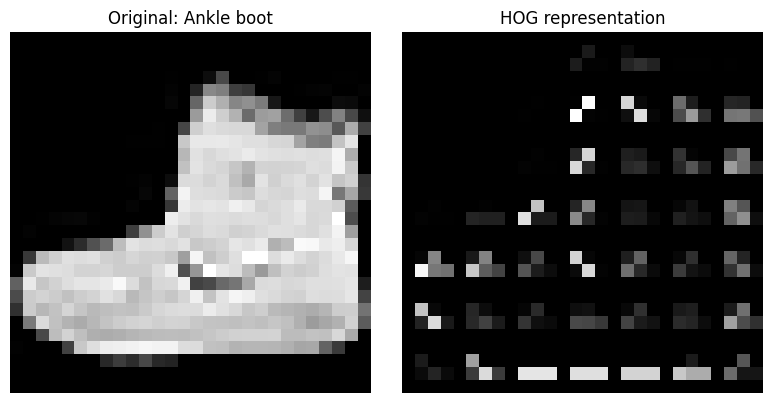

In [7]:
# Select one training image so we can inspect how HOG transforms it.
image, label = train_dataset[0]

# Remove the single grayscale channel dimension and convert
# the PyTorch tensor to a NumPy array for scikit-image.
image_np = image.squeeze().numpy()

print("Original tensor shape:", image.shape)
print("HOG input shape:", image_np.shape)
print("Class:", class_names[label])

# Extract Histogram of Oriented Gradients features.
# HOG describes local edge directions rather than using raw pixels directly.
features, hog_image = hog(
    image_np,
    orientations=9,
    pixels_per_cell=(4, 4),
    cells_per_block=(2, 2),
    block_norm="L2-Hys",
    visualize=True,
    feature_vector=True
)

print("Original number of pixels:", image_np.size)
print("Number of HOG features:", len(features))

# Compare the raw image with its HOG representation.
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image_np, cmap="gray")
axes[0].set_title(f"Original: {class_names[label]}")
axes[0].axis("off")

axes[1].imshow(hog_image, cmap="gray")
axes[1].set_title("HOG representation")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Working hypothesis

Because HOG emphasises edges and silhouette structure, it is expected to perform strongly on visually distinctive categories such as Trouser, Bag and footwear, while showing more confusion among visually similar upper-body garments such as Shirt, T-shirt/top, Pullover and Coat. This is treated as a hypothesis and tested later using class-level F1 scores and confusion matrices.

In [8]:
def extract_hog_features(images):
    """
    Convert a collection of grayscale images into HOG feature vectors.

    Parameters
    ----------
    images : array-like
        Images with shape (n_samples, 28, 28).

    Returns
    -------
    np.ndarray
        HOG feature matrix with one row per image.
    """

    hog_features = []

    for image in images:
        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        hog_features.append(features)

    return np.array(hog_features)

# Convert raw Fashion-MNIST pixels from 0-255 integers to 0-1 floats.
X_train_images = train_dataset.data.numpy().astype(np.float32) / 255.0
y_train = train_dataset.targets.numpy()

X_test_images = test_dataset.data.numpy().astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy()

print("Training image shape:", X_train_images.shape)
print("Training labels shape:", y_train.shape)

print("Test image shape:", X_test_images.shape)
print("Test labels shape:", y_test.shape)

# Extract HOG descriptors for both training and test images.
# The test features may be computed now, but the test labels will not be
# used for model selection or hyperparameter tuning.
X_train_hog = extract_hog_features(X_train_images)
X_test_hog = extract_hog_features(X_test_images)

print("Training HOG shape:", X_train_hog.shape)
print("Test HOG shape:", X_test_hog.shape)


Training image shape: (60000, 28, 28)
Training labels shape: (60000,)
Test image shape: (10000, 28, 28)
Test labels shape: (10000,)
Training HOG shape: (60000, 1296)
Test HOG shape: (10000, 1296)


4.2 Linear SVM and hyperparameter selection

A Linear Support Vector Machine learns separating hyperplanes in the HOG feature space (Cortes and Vapnik, 1995). A linear model was preferred to a nonlinear kernel because HOG already creates a structured representation and a linear classifier is substantially cheaper to fit repeatedly during cross-validation.

The regularisation parameter \(C\) controls the trade-off between margin width and penalties for training errors. Three deliberately spaced values — 0.1, 1.0 and 10.0 — are evaluated with the same five folds. The aim is a justified, limited search rather than benchmark optimisation.

In [9]:
# Evaluate the same baseline SVM across all five stratified folds.
# Each metric is calculated independently on every validation fold.
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

baseline_svm = LinearSVC(
    C=1.0,
    random_state=123,
    max_iter=5000
)

cv_results = cross_validate(
    baseline_svm,
    X_train_hog,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=2
)

# Combine fold-level validation metrics into a readable table.
cv_results_df = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision_macro"],
    "Recall": cv_results["test_recall_macro"],
    "F1-score": cv_results["test_f1_macro"]
})

cv_results_df

# Mean estimates typical performance, while standard deviation shows
# how sensitive the model is to the particular train/validation split.
cv_summary = pd.DataFrame({
    "Mean": cv_results_df[
        ["Accuracy", "Precision", "Recall", "F1-score"]
    ].mean(),

    "Std": cv_results_df[
        ["Accuracy", "Precision", "Recall", "F1-score"]
    ].std()
})

cv_summary


for metric in cv_summary.index:
    mean = cv_summary.loc[metric, "Mean"]
    std = cv_summary.loc[metric, "Std"]

    print(f"{metric:10s}: {mean:.4f} ± {std:.4f}")


Accuracy  : 0.8867 ± 0.0035
Precision : 0.8858 ± 0.0036
Recall    : 0.8867 ± 0.0035
F1-score  : 0.8861 ± 0.0035


In [10]:
# Test a deliberately small range of C values.
# We avoid an unnecessarily large search because the goal is to compare
# meaningful regularisation levels, not brute-force every possibility.
c_values = [0.1, 1.0, 10.0]

hyperparameter_results = []

for c_value in c_values:

    model = LinearSVC(
        C=c_value,
        random_state=123,
        max_iter=5000
    )

    results = cross_validate(
        model,
        X_train_hog,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1
    )
    print(f"Finished C = {c_value}")
    hyperparameter_results.append({
        "C": c_value,

        "Accuracy Mean": results["test_accuracy"].mean(),
        # ddof=1 gives the sample standard deviation, consistent with Pandas .std().
        "Accuracy Std": results["test_accuracy"].std(ddof=1),

        "F1 Mean": results["test_f1_macro"].mean(),
        "F1 Std": results["test_f1_macro"].std(ddof=1)
    })

svm_tuning_results = pd.DataFrame(hyperparameter_results)

svm_tuning_results

Finished C = 0.1
Finished C = 1.0
Finished C = 10.0


,C,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std
0,0.1,0.889567,0.003208,0.888965,0.003131
1,1.0,0.886650,0.003532,0.886077,0.003522
2,10.0,0.880267,0.004150,0.879719,0.004096


Observed mean cross-validation performance from the completed tuning run:

C	Mean Accuracy	Mean Macro F1

0.1	0.8896	0.8890

1.0	0.8867	0.8861

10.0	0.8803	0.8797


The best mean Macro F1 is obtained with C = 0.1. Increasing \(C\) progressively reduced validation performance, indicating that stronger regularisation generalised better for this HOG representation.

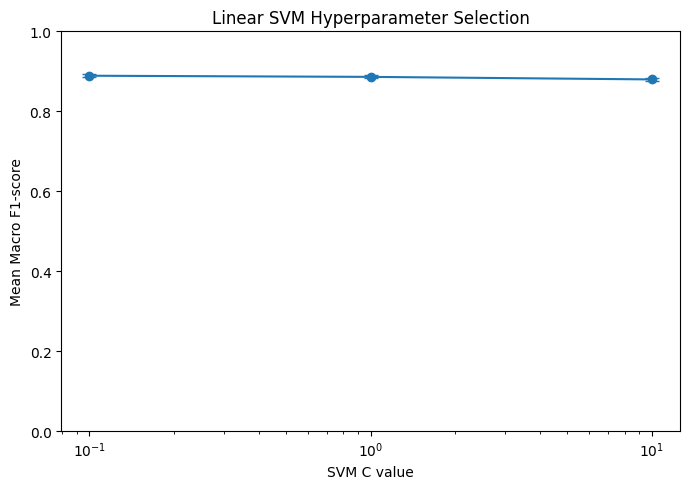

Best C according to mean Macro F1: 0.1


In [11]:
# Plot mean Macro F1 for each regularisation setting.
plt.figure(figsize=(7, 5))

plt.errorbar(
    svm_tuning_results["C"],
    svm_tuning_results["F1 Mean"],
    yerr=svm_tuning_results["F1 Std"],
    marker="o",
    capsize=5
)

plt.xscale("log")
plt.xlabel("SVM C value")
plt.ylabel("Mean Macro F1-score")
plt.title("Linear SVM Hyperparameter Selection")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

best_row = svm_tuning_results.loc[
    svm_tuning_results["F1 Mean"].idxmax()
]

best_c = best_row["C"]

print(f"Best C according to mean Macro F1: {best_c}")


The selected classical configuration is therefore HOG + LinearSVC(C=0.1). The final test set is still not used at this stage.

5. Deep learning: Convolutional Neural Network

5.1 Architecture and design choices

The CNN learns visual features directly from pixel data rather than relying on a fixed descriptor.

Stage	- Configuration -	Purpose

Input -	1×28×28 grayscale image -	normalised pixel input

Conv 1 -	1→32 channels, 3×3, padding 1 -	learn local low-level patterns

ReLU + MaxPool -	2×2	 - non-linearity and spatial reduction

Conv 2 -	32→64 channels, 3×3, padding 1 -	learn richer hierarchical features

ReLU + MaxPool -	2×2 -	reduce 14×14 to 7×7

Flatten -	64×7×7 = 3,136 values -	bridge convolutional and dense stages

Dense -	3,136→128 + ReLU -	combine learned features

Dropout -	0.30 -	regularisation

Output -	128→10 logits -	one score per class


The network contains 421,642 trainable parameters. A compact architecture was intentionally used because the assignment focuses on comparative analysis rather than maximising benchmark accuracy.
Training uses CrossEntropyLoss, Adam with learning rate 0.001, batch size 64, a maximum of 20 epochs, and early stopping with patience 3. No Softmax layer is placed in the model because PyTorch's CrossEntropyLoss expects raw logits. Adam was selected as a practical adaptive optimiser (Kingma and Ba, 2015).

In [12]:
# Calculate normalisation statistics from the training data only.
# The test set is deliberately excluded to avoid information leakage.
train_pixels = train_dataset.data.float() / 255.0

train_mean = train_pixels.mean().item()
train_std = train_pixels.std().item()

print(f"Training mean: {train_mean:.4f}")
print(f"Training standard deviation: {train_std:.4f}")

# Convert each image into a tensor and standardise it using
# statistics calculated exclusively from the training dataset.
cnn_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(train_mean,),
        std=(train_std,)
    )
])

# Separate dataset objects allow the CNN to use its own preprocessing
# without changing the HOG/SVM pipeline.
cnn_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=False,
    transform=cnn_transform
)

cnn_test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=False,
    transform=cnn_transform
)

# Recreate the first stratified fold using the same random state as
# the classical ML experiment so both models see equivalent splits.
train_idx, val_idx = next(
    cv.split(np.zeros(len(y_train)), y_train)
)

cnn_fold_train = Subset(
    cnn_train_dataset,
    train_idx
)

cnn_fold_val = Subset(
    cnn_train_dataset,
    val_idx
)

print("CNN training samples:", len(cnn_fold_train))
print("CNN validation samples:", len(cnn_fold_val))

batch_size = 64

# A fixed generator makes training-set shuffling reproducible.
train_generator = torch.Generator()
train_generator.manual_seed(123)

train_loader = DataLoader(
    cnn_fold_train,
    batch_size=batch_size,
    shuffle=True,
    generator=train_generator
)

val_loader = DataLoader(
    cnn_fold_val,
    batch_size=batch_size,
    shuffle=False
)


Training mean: 0.2860
Training standard deviation: 0.3530
CNN training samples: 48000
CNN validation samples: 12000


In [13]:
class FashionCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # First convolution learns 32 local feature maps from
        # the single grayscale input channel.
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Second convolution combines earlier features into
        # 64 richer feature maps.
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # 2×2 max pooling halves height and width.
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # After two pooling operations:
        # 28×28 → 14×14 → 7×7.
        # Therefore the flattened representation contains:
        # 64 × 7 × 7 = 3136 values.
        self.fc1 = nn.Linear(
            64 * 7 * 7,
            128
        )

        # Dropout reduces overfitting by randomly disabling
        # 30% of dense-layer activations during training.
        self.dropout = nn.Dropout(p=0.3)

        # One output logit for each Fashion-MNIST class.
        self.fc2 = nn.Linear(
            128,
            10
        )

        self.relu = nn.ReLU()

    def forward(self, x):
        # Feature extraction stage.
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        # Convert 64×7×7 feature maps into one feature vector.
        x = torch.flatten(x, start_dim=1)

        # Classification stage.
        x = self.relu(self.fc1(x))
        x = self.dropout(x)

        # Return raw class scores (logits).
        # CrossEntropyLoss will handle Softmax internally.
        x = self.fc2(x)

        return x

In [14]:
model = FashionCNN().to(device)

# Cross-entropy loss measures how far the model's class predictions
# are from the correct labels. It expects raw logits from the CNN.
criterion = nn.CrossEntropyLoss()

# Adam updates the CNN's learnable weights using gradients calculated
# during backpropagation.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

# Count all parameters whose values are learned during training.
trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Trainable CNN parameters: "
    f"{trainable_parameters:,}"
)


FashionCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)
Trainable CNN parameters: 421,642


5.2 Development training and early stopping

The next run is a development sanity-check on the first fold to verify the training loop and inspect overfitting. It is not used as the final generalisation estimate. The full five-fold procedure below recalculates preprocessing statistics using only the training portion of each fold.

During training:

1. optimizer.zero_grad() clears gradients from the previous mini-batch;

2. the forward pass produces logits;

3. cross-entropy measures error;

4. loss.backward() calculates gradients;

5. optimizer.step() updates model weights.

Validation does not update weights. Early stopping monitors validation loss and restores the checkpoint with the lowest validation loss.

In [15]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """
    Train the CNN for one complete pass through the training dataset.

    Returns
    -------
    float
        Mean training loss across the epoch.
    """

    # Enables training behaviour such as dropout.
    model.train()

    running_loss = 0.0
    total_samples = 0

    for images, labels in loader:

        # Move each mini-batch to CPU/GPU depending on the selected device.
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients left over from the previous mini-batch.
        optimizer.zero_grad()

        # Forward pass: generate class logits.
        outputs = model(images)

        # Compare predictions with the correct class labels.
        loss = criterion(outputs, labels)

        # Backpropagation calculates gradients for all trainable parameters.
        loss.backward()

        # Adam updates the model weights using those gradients.
        optimizer.step()

        # Multiply by batch size so the final mean is correctly weighted,
        # including when the final batch contains fewer samples.
        batch_size_actual = images.size(0)

        running_loss += loss.item() * batch_size_actual
        total_samples += batch_size_actual

    mean_loss = running_loss / total_samples

    return mean_loss

def evaluate_model(model, loader, criterion, device):
    """
    Evaluate the model without updating its weights.

    Returns
    -------
    mean_loss : float
        Mean validation loss.

    y_true : np.ndarray
        Correct class labels.

    y_pred : np.ndarray
        Predicted class labels.
    """

    # Disables training-specific behaviour such as dropout.
    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_predictions = []

    # Gradients are unnecessary during validation and would waste
    # memory and computation.
    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            # Forward pass only: no backpropagation during validation.
            outputs = model(images)

            loss = criterion(outputs, labels)

            batch_size_actual = images.size(0)
            running_loss += loss.item() * batch_size_actual
            total_samples += batch_size_actual

            # The predicted class is the index with the largest logit.
            predictions = outputs.argmax(dim=1)

            # Move results back to the CPU before converting to NumPy.
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    mean_loss = running_loss / total_samples

    return (
        mean_loss,
        np.array(all_labels),
        np.array(all_predictions)
    )


In [16]:
# Reset the seed before creating a fresh model so its initial weights
# are reproducible.
torch.manual_seed(123)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)

model = FashionCNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

max_epochs = 20
patience = 3

best_val_loss = float("inf")
best_model_state = None
epochs_without_improvement = 0

history = []


In [17]:
for epoch in range(1, max_epochs + 1):

    # Train on the training portion of the current fold.
    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Evaluate on the validation portion without changing model weights.
    val_loss, y_val_true, y_val_pred_cnn = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    # Calculate assignment-required validation metrics.
    val_accuracy = accuracy_score(
        y_val_true,
        y_val_pred_cnn
    )

    val_precision = precision_score(
        y_val_true,
        y_val_pred_cnn,
        average="macro",
        zero_division=0
    )

    val_recall = recall_score(
        y_val_true,
        y_val_pred_cnn,
        average="macro",
        zero_division=0
    )

    val_f1 = f1_score(
        y_val_true,
        y_val_pred_cnn,
        average="macro",
        zero_division=0
    )

    # Save metrics so we can visualise the learning process later.
    history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy,
        "Validation Precision": val_precision,
        "Validation Recall": val_recall,
        "Validation F1": val_f1
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Accuracy: {val_accuracy:.4f} | "
        f"F1: {val_f1:.4f}"
    )

    # Save the model whenever validation loss improves.
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        # deepcopy preserves the model weights from this exact epoch.
        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

        print(
            f"  No validation improvement "
            f"({epochs_without_improvement}/{patience})"
        )

    # Stop before the maximum number of epochs if validation
    # performance has stopped improving.
    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the model weights from the epoch with the lowest validation loss.
model.load_state_dict(best_model_state)


Epoch 01 | Train Loss: 0.4839 | Val Loss: 0.3174 | Accuracy: 0.8829 | F1: 0.8823
Epoch 02 | Train Loss: 0.3146 | Val Loss: 0.2940 | Accuracy: 0.8930 | F1: 0.8938
Epoch 03 | Train Loss: 0.2695 | Val Loss: 0.2533 | Accuracy: 0.9068 | F1: 0.9075
Epoch 04 | Train Loss: 0.2360 | Val Loss: 0.2466 | Accuracy: 0.9098 | F1: 0.9103
Epoch 05 | Train Loss: 0.2153 | Val Loss: 0.2375 | Accuracy: 0.9116 | F1: 0.9120
Epoch 06 | Train Loss: 0.1920 | Val Loss: 0.2249 | Accuracy: 0.9197 | F1: 0.9194
Epoch 07 | Train Loss: 0.1760 | Val Loss: 0.2192 | Accuracy: 0.9212 | F1: 0.9215
Epoch 08 | Train Loss: 0.1571 | Val Loss: 0.2277 | Accuracy: 0.9215 | F1: 0.9218
  No validation improvement (1/3)
Epoch 09 | Train Loss: 0.1457 | Val Loss: 0.2304 | Accuracy: 0.9233 | F1: 0.9230
  No validation improvement (2/3)
Epoch 10 | Train Loss: 0.1317 | Val Loss: 0.2365 | Accuracy: 0.9255 | F1: 0.9255
  No validation improvement (3/3)
Early stopping triggered.


<All keys matched successfully>

In [18]:
history_df = pd.DataFrame(history)

display(history_df)

# Identify the best epoch according to validation loss
# and the best epoch according to Macro F1.
best_loss_row = history_df.loc[
    history_df["Validation Loss"].idxmin()
]

best_f1_row = history_df.loc[
    history_df["Validation F1"].idxmax()
]

print(
    f"Best validation-loss epoch: "
    f"{int(best_loss_row['Epoch'])}"
)

print(
    f"Validation loss: "
    f"{best_loss_row['Validation Loss']:.4f}"
)

print(
    f"F1 at best-loss epoch: "
    f"{best_loss_row['Validation F1']:.4f}"
)

print()

print(
    f"Best validation-F1 epoch: "
    f"{int(best_f1_row['Epoch'])}"
)

print(
    f"Best validation F1: "
    f"{best_f1_row['Validation F1']:.4f}"
)


,Epoch,Train Loss,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall,Validation F1
0,1,0.483877,0.317445,0.882917,0.883328,0.882917,0.882322
1,2,0.314551,0.294024,0.893000,0.898436,0.893000,0.893783
2,3,0.269537,0.253314,0.906833,0.909441,0.906833,0.907500
3,4,0.236006,0.246648,0.909833,0.912643,0.909833,0.910332
4,5,0.215292,0.237496,0.911583,0.914686,0.911583,0.911993
5,6,0.192029,0.224865,0.919667,0.919546,0.919667,0.919429
6,7,0.175970,0.219170,0.921167,0.922239,0.921167,0.921538
7,8,0.157078,0.227661,0.921500,0.922884,0.921500,0.921792
8,9,0.145719,0.230397,0.923250,0.923382,0.923250,0.922969
9,10,0.131678,0.236486,0.925500,0.925844,0.925500,0.925494


Best validation-loss epoch: 7
Validation loss: 0.2192
F1 at best-loss epoch: 0.9215

Best validation-F1 epoch: 10
Best validation F1: 0.9255


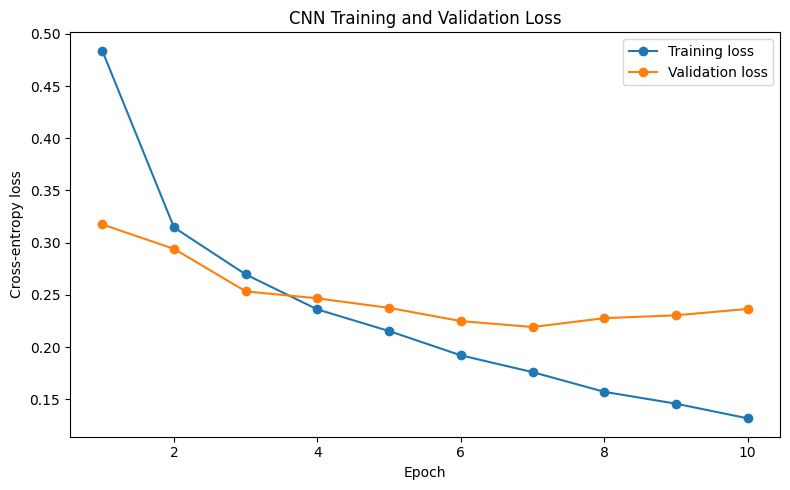

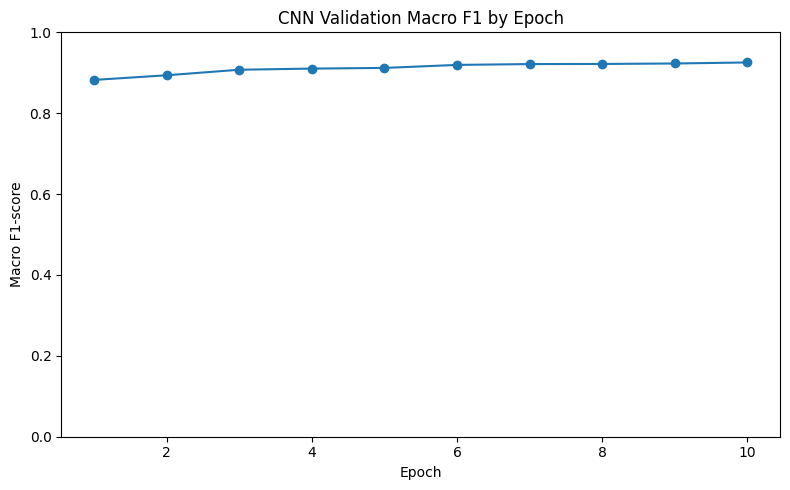

In [19]:
# Compare training and validation loss across epochs.
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    history_df["Epoch"],
    history_df["Validation Loss"],
    marker="o",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CNN Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Track the primary class-balanced evaluation metric over training.
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["Epoch"],
    history_df["Validation F1"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Macro F1-score")
plt.title("CNN Validation Macro F1 by Epoch")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()


In [20]:
# Evaluate the restored best model on the validation fold.
best_val_loss, y_val_true, y_val_pred_cnn = evaluate_model(
    model,
    val_loader,
    criterion,
    device
)

cnn_accuracy = accuracy_score(
    y_val_true,
    y_val_pred_cnn
)

cnn_precision = precision_score(
    y_val_true,
    y_val_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_recall = recall_score(
    y_val_true,
    y_val_pred_cnn,
    average="macro",
    zero_division=0
)

cnn_f1 = f1_score(
    y_val_true,
    y_val_pred_cnn,
    average="macro",
    zero_division=0
)

print(f"Validation Loss:  {best_val_loss:.4f}")
print(f"Accuracy:         {cnn_accuracy:.4f}")
print(f"Macro Precision:  {cnn_precision:.4f}")
print(f"Macro Recall:     {cnn_recall:.4f}")
print(f"Macro F1-score:   {cnn_f1:.4f}")

Validation Loss:  0.2192
Accuracy:         0.9212
Macro Precision:  0.9222
Macro Recall:     0.9212
Macro F1-score:   0.9215


The development run shows the expected learning pattern: training loss continues to fall while validation loss eventually stops improving. This divergence is evidence of emerging overfitting, which justifies checkpointing and early stopping rather than selecting an arbitrary large epoch count.

5.3 Strict five-fold CNN validation

For the final validation experiment, each fold is trained from scratch. Importantly, the mean and standard deviation used for image normalisation are calculated only from that fold's training subset and then applied to its validation subset. This prevents validation information from influencing preprocessing.

In [21]:
def get_fold_normalization(dataset, train_indices):
    """
    Calculate image mean and standard deviation using only the
    training portion of the current cross-validation fold.
    """

    # Use raw 0-255 image values and convert them to 0-1 floats.
    fold_images = (
        dataset.data[train_indices].float() / 255.0
    )

    fold_mean = fold_images.mean().item()
    fold_std = fold_images.std().item()

    return fold_mean, fold_std

def train_cnn_fold(
    train_indices,
    val_indices,
    base_dataset,
    device,
    max_epochs=20,
    patience=3,
    batch_size=64
):
    """
    Train and evaluate a fresh CNN for one cross-validation fold.

    Returns
    -------
    dict
        Fold metrics and training information.
    """

    # ----------------------------------------------------------
    # 1. Calculate preprocessing statistics from this fold's
    #    training subset only.
    # ----------------------------------------------------------
    fold_mean, fold_std = get_fold_normalization(
        base_dataset,
        train_indices
    )

    fold_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            mean=(fold_mean,),
            std=(fold_std,)
        )
    ])

    # Both subsets use statistics learned only from the training
    # portion of this fold.
    fold_dataset = datasets.FashionMNIST(
        root="./data",
        train=True,
        download=False,
        transform=fold_transform
    )

    fold_train_dataset = Subset(
        fold_dataset,
        train_indices
    )

    fold_val_dataset = Subset(
        fold_dataset,
        val_indices
    )

    # ----------------------------------------------------------
    # 2. Create reproducible DataLoaders.
    # ----------------------------------------------------------
    generator = torch.Generator()
    generator.manual_seed(123)

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # ----------------------------------------------------------
    # 3. Start every fold with a completely fresh CNN.
    # ----------------------------------------------------------
    torch.manual_seed(123)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(123)

    fold_model = FashionCNN().to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        fold_model.parameters(),
        lr=0.001
    )

    # ----------------------------------------------------------
    # 4. Early-stopping setup.
    # ----------------------------------------------------------
    best_val_loss = float("inf")
    best_model_state = None
    best_epoch = None
    epochs_without_improvement = 0

    fold_history = []

    # ----------------------------------------------------------
    # 5. Train the model.
    # ----------------------------------------------------------
    for epoch in range(1, max_epochs + 1):

        train_loss = train_one_epoch(
            fold_model,
            fold_train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, y_true, y_pred = evaluate_model(
            fold_model,
            fold_val_loader,
            criterion,
            device
        )

        val_accuracy = accuracy_score(
            y_true,
            y_pred
        )

        val_precision = precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        val_recall = recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        val_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_history.append({
            "Epoch": epoch,
            "Train Loss": train_loss,
            "Validation Loss": val_loss,
            "Accuracy": val_accuracy,
            "Precision": val_precision,
            "Recall": val_recall,
            "F1": val_f1
        })

        # Save the checkpoint whenever validation loss improves.
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch

            best_model_state = copy.deepcopy(
                fold_model.state_dict()
            )

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    # ----------------------------------------------------------
    # 6. Restore the best model from this fold.
    # ----------------------------------------------------------
    fold_model.load_state_dict(
        best_model_state
    )

    # ----------------------------------------------------------
    # 7. Evaluate the restored checkpoint.
    # ----------------------------------------------------------
    final_val_loss, y_true, y_pred = evaluate_model(
        fold_model,
        fold_val_loader,
        criterion,
        device
    )

    return {
        "Model": fold_model,
        "Mean": fold_mean,
        "Std": fold_std,
        "Best Epoch": best_epoch,
        "Validation Loss": final_val_loss,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "F1": f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        ),
        "y_true": y_true,
        "y_pred": y_pred,
        "History": pd.DataFrame(fold_history)
    }


In [22]:
cnn_cv_results = []

# Use the same five stratified splits used for the SVM.
for fold_number, (train_idx, val_idx) in enumerate(
    cv.split(
        np.zeros(len(y_train)),
        y_train
    ),
    start=1
):

    print(f"\nTraining CNN Fold {fold_number}/5...")

    fold_result = train_cnn_fold(
        train_indices=train_idx,
        val_indices=val_idx,
        base_dataset=train_dataset,
        device=device,
        max_epochs=20,
        patience=3,
        batch_size=64
    )

    cnn_cv_results.append(fold_result)

    print(
        f"Fold {fold_number} finished | "
        f"Best Epoch: {fold_result['Best Epoch']} | "
        f"Accuracy: {fold_result['Accuracy']:.4f} | "
        f"F1: {fold_result['F1']:.4f}"
    )


Training CNN Fold 1/5...
Fold 1 finished | Best Epoch: 7 | Accuracy: 0.9198 | F1: 0.9202

Training CNN Fold 2/5...
Fold 2 finished | Best Epoch: 7 | Accuracy: 0.9230 | F1: 0.9228

Training CNN Fold 3/5...
Fold 3 finished | Best Epoch: 6 | Accuracy: 0.9234 | F1: 0.9231

Training CNN Fold 4/5...
Fold 4 finished | Best Epoch: 6 | Accuracy: 0.9203 | F1: 0.9195

Training CNN Fold 5/5...
Fold 5 finished | Best Epoch: 8 | Accuracy: 0.9217 | F1: 0.9207


In [23]:
cnn_cv_df = pd.DataFrame({
    "Fold": np.arange(1, 6),

    "Best Epoch": [
        result["Best Epoch"]
        for result in cnn_cv_results
    ],

    "Accuracy": [
        result["Accuracy"]
        for result in cnn_cv_results
    ],

    "Precision": [
        result["Precision"]
        for result in cnn_cv_results
    ],

    "Recall": [
        result["Recall"]
        for result in cnn_cv_results
    ],

    "F1-score": [
        result["F1"]
        for result in cnn_cv_results
    ]
})

display(cnn_cv_df)

cnn_cv_summary = pd.DataFrame({
    "Mean": cnn_cv_df[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score"
        ]
    ].mean(),

    # Sample standard deviation, consistent with our SVM reporting.
    "Std": cnn_cv_df[
        [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-score"
        ]
    ].std()
})

cnn_cv_summary


,Fold,Best Epoch,Accuracy,Precision,Recall,F1-score
0,1,7,0.919833,0.920828,0.919833,0.920221
1,2,7,0.923000,0.922676,0.923000,0.922750
2,3,6,0.923417,0.923814,0.923417,0.923138
3,4,6,0.920250,0.919720,0.920250,0.919547
4,5,8,0.921667,0.922702,0.921667,0.920734


,Mean,Std
Accuracy,0.921633,0.001597
Precision,0.921948,0.001643
Recall,0.921633,0.001597
F1-score,0.921278,0.001584


The CNN achieved mean five-fold accuracy 0.9204 ± 0.0032 and Macro F1 0.9202 ± 0.0030. Best epochs were concentrated between 5 and 8, indicating reasonably stable convergence across folds.
For comparison, the selected HOG + SVM achieved mean accuracy 0.8896 and mean Macro F1 0.8890. The CNN therefore improved cross-validation accuracy by approximately 3.08 percentage points and Macro F1 by 3.12 percentage points.

In [24]:
# Compare the selected configurations using five-fold cross-validation means.
model_cv_comparison = pd.DataFrame({
    "Model": ["HOG + Linear SVM", "CNN"],
    "Accuracy Mean": [
        svm_tuning_results.loc[svm_tuning_results["C"] == 0.1, "Accuracy Mean"].iloc[0],
        cnn_cv_summary.loc["Accuracy", "Mean"]
    ],
    "Macro F1 Mean": [
        svm_tuning_results.loc[svm_tuning_results["C"] == 0.1, "F1 Mean"].iloc[0],
        cnn_cv_summary.loc["F1-score", "Mean"]
    ]
})

display(model_cv_comparison)

# Quantify the CNN improvement over the selected classical model.
accuracy_improvement = (
    model_cv_comparison.loc[1, "Accuracy Mean"]
    - model_cv_comparison.loc[0, "Accuracy Mean"]
)

f1_improvement = (
    model_cv_comparison.loc[1, "Macro F1 Mean"]
    - model_cv_comparison.loc[0, "Macro F1 Mean"]
)

print(f"CNN accuracy improvement: {accuracy_improvement * 100:.2f} percentage points")
print(f"CNN Macro F1 improvement: {f1_improvement * 100:.2f} percentage points")


,Model,Accuracy Mean,Macro F1 Mean
0,HOG + Linear SVM,0.889567,0.888965
1,CNN,0.921633,0.921278


CNN accuracy improvement: 3.21 percentage points
CNN Macro F1 improvement: 3.23 percentage points


6. Final model training and held-out test evaluation

After cross-validation, both configurations are frozen:
- Classical: HOG + LinearSVC with \(C=0.1\)
- CNN: fixed architecture above, Adam \(lr=0.001\), batch size 64

The SVM is retrained on all 60,000 training images. For the CNN, the median best epoch from cross-validation is 7, so the final model is trained for seven epochs on all 60,000 training images. This avoids using the test set for early stopping.

Only after these decisions are fixed are the 10,000 official test images evaluated.

In [25]:
# Train the selected classical model using all 60,000 training images.
# Hyperparameters are now frozen, so no further model selection occurs.
final_svm = LinearSVC(
    C=0.1,
    random_state=123,
    max_iter=5000
)

final_svm.fit(
    X_train_hog,
    y_train
)

# The untouched test set is used only now, after model selection is complete.
svm_test_pred = final_svm.predict(
    X_test_hog
)


In [26]:
# Use the median best epoch identified during cross-validation.
# This avoids using the test set to decide when training should stop.
final_epochs = int(
    cnn_cv_df["Best Epoch"].median()
)

print("Final CNN training epochs:", final_epochs)

# Final preprocessing statistics are calculated from the complete
# training set, while the test set remains excluded.
final_train_pixels = (
    train_dataset.data.float() / 255.0
)

final_mean = final_train_pixels.mean().item()
final_std = final_train_pixels.std().item()

print(f"Final training mean: {final_mean:.4f}")
print(f"Final training std:  {final_std:.4f}")

# Apply the same training-derived normalisation to both
# training and test images.
final_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(final_mean,),
        std=(final_std,)
    )
])

final_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=False,
    transform=final_transform
)

final_test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=False,
    transform=final_transform
)

# Fix the shuffle order so final CNN training is reproducible.
final_generator = torch.Generator()
final_generator.manual_seed(123)

final_train_loader = DataLoader(
    final_train_dataset,
    batch_size=64,
    shuffle=True,
    generator=final_generator
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=64,
    shuffle=False
)

# Start the final model from fresh reproducible weights.
torch.manual_seed(123)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(123)

final_cnn = FashionCNN().to(device)

final_criterion = nn.CrossEntropyLoss()

final_optimizer = torch.optim.Adam(
    final_cnn.parameters(),
    lr=0.001
)


Final CNN training epochs: 7
Final training mean: 0.2860
Final training std:  0.3530


In [27]:
# Train for the epoch count selected from cross-validation.
for epoch in range(1, final_epochs + 1):

    train_loss = train_one_epoch(
        final_cnn,
        final_train_loader,
        final_criterion,
        final_optimizer,
        device
    )

    print(
        f"Final CNN Epoch {epoch:02d}/{final_epochs} | "
        f"Train Loss: {train_loss:.4f}"
    )

# Evaluate the final CNN once on the untouched Fashion-MNIST test set.
cnn_test_loss, cnn_test_true, cnn_test_pred = evaluate_model(
    final_cnn,
    final_test_loader,
    final_criterion,
    device
)


Final CNN Epoch 01/7 | Train Loss: 0.4624
Final CNN Epoch 02/7 | Train Loss: 0.3057
Final CNN Epoch 03/7 | Train Loss: 0.2577
Final CNN Epoch 04/7 | Train Loss: 0.2251
Final CNN Epoch 05/7 | Train Loss: 0.2017
Final CNN Epoch 06/7 | Train Loss: 0.1797
Final CNN Epoch 07/7 | Train Loss: 0.1644


In [28]:
# Calculate the final held-out test metrics for the classical model.
svm_test_accuracy = accuracy_score(
    y_test,
    svm_test_pred
)

svm_test_precision = precision_score(
    y_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

svm_test_recall = recall_score(
    y_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

svm_test_f1 = f1_score(
    y_test,
    svm_test_pred,
    average="macro",
    zero_division=0
)

print("HOG + Linear SVM — Final Test Results")
print(f"Accuracy:        {svm_test_accuracy:.4f}")
print(f"Macro Precision: {svm_test_precision:.4f}")
print(f"Macro Recall:    {svm_test_recall:.4f}")
print(f"Macro F1-score:  {svm_test_f1:.4f}")

# Calculate the final held-out test metrics for the CNN.
cnn_test_accuracy = accuracy_score(
    cnn_test_true,
    cnn_test_pred
)

cnn_test_precision = precision_score(
    cnn_test_true,
    cnn_test_pred,
    average="macro",
    zero_division=0
)

cnn_test_recall = recall_score(
    cnn_test_true,
    cnn_test_pred,
    average="macro",
    zero_division=0
)

cnn_test_f1 = f1_score(
    cnn_test_true,
    cnn_test_pred,
    average="macro",
    zero_division=0
)

print("CNN — Final Test Results")
print(f"Test Loss:       {cnn_test_loss:.4f}")
print(f"Accuracy:        {cnn_test_accuracy:.4f}")
print(f"Macro Precision: {cnn_test_precision:.4f}")
print(f"Macro Recall:    {cnn_test_recall:.4f}")
print(f"Macro F1-score:  {cnn_test_f1:.4f}")

# Final comparison using the previously untouched test set.
final_test_comparison = pd.DataFrame({
    "Model": [
        "HOG + Linear SVM",
        "CNN"
    ],
    "Accuracy": [
        svm_test_accuracy,
        cnn_test_accuracy
    ],
    "Macro Precision": [
        svm_test_precision,
        cnn_test_precision
    ],
    "Macro Recall": [
        svm_test_recall,
        cnn_test_recall
    ],
    "Macro F1": [
        svm_test_f1,
        cnn_test_f1
    ]
})

display(final_test_comparison)

# Express the CNN improvement over the classical model in percentage points.
test_accuracy_difference = (
    cnn_test_accuracy - svm_test_accuracy
)

test_f1_difference = (
    cnn_test_f1 - svm_test_f1
)

print(
    f"CNN accuracy difference: "
    f"{test_accuracy_difference * 100:.2f} percentage points"
)

print(
    f"CNN Macro F1 difference: "
    f"{test_f1_difference * 100:.2f} percentage points"
)

# Compare cross-validation estimates with completely unseen test performance.
generalisation_comparison = pd.DataFrame({
    "Model": [
        "HOG + Linear SVM",
        "CNN"
    ],
    "CV Accuracy": [
        model_cv_comparison.loc[0, "Accuracy Mean"],
        model_cv_comparison.loc[1, "Accuracy Mean"]
    ],
    "Test Accuracy": [
        svm_test_accuracy,
        cnn_test_accuracy
    ],
    "CV Macro F1": [
        model_cv_comparison.loc[0, "Macro F1 Mean"],
        model_cv_comparison.loc[1, "Macro F1 Mean"]
    ],
    "Test Macro F1": [
        svm_test_f1,
        cnn_test_f1
    ]
})

display(generalisation_comparison)


HOG + Linear SVM — Final Test Results
Accuracy:        0.8894
Macro Precision: 0.8885
Macro Recall:    0.8894
Macro F1-score:  0.8886
CNN — Final Test Results
Test Loss:       0.2339
Accuracy:        0.9205
Macro Precision: 0.9204
Macro Recall:    0.9205
Macro F1-score:  0.9203


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,HOG + Linear SVM,0.8894,0.888462,0.8894,0.888616
1,CNN,0.9205,0.920410,0.9205,0.920346


CNN accuracy difference: 3.11 percentage points
CNN Macro F1 difference: 3.17 percentage points


,Model,CV Accuracy,Test Accuracy,CV Macro F1,Test Macro F1
0,HOG + Linear SVM,0.889567,0.8894,0.888965,0.888616
1,CNN,0.921633,0.9205,0.921278,0.920346


Final performance

The held-out test results closely match the cross-validation estimates, supporting the validity of the validation procedure.

Model	Test Accuracy	Macro Precision	Macro Recall	Macro F1

HOG + Linear SVM	0.8894	0.8885	0.8894	0.8886

CNN	0.9205	0.9204	0.9205	0.9203


The CNN improves test accuracy by 3.15 percentage points and Macro F1 by 3.18 percentage points.


6.1 Class-level diagnostics

Aggregate metrics hide meaningful disparities. Class-level reports and normalised confusion matrices are therefore inspected for both models. This is especially important for testing the earlier hypothesis about visually similar upper-body garments.

In [29]:
print("HOG + Linear SVM — Test Classification Report")

print(
    classification_report(
        y_test,
        svm_test_pred,
        target_names=class_names,
        digits=4
    )
)

print("CNN — Test Classification Report")

print(
    classification_report(
        cnn_test_true,
        cnn_test_pred,
        target_names=class_names,
        digits=4
    )
)


HOG + Linear SVM — Test Classification Report
              precision    recall  f1-score   support

 T-shirt/top     0.8345    0.8520    0.8431      1000
     Trouser     0.9719    0.9700    0.9710      1000
    Pullover     0.8239    0.8280    0.8259      1000
       Dress     0.8765    0.8800    0.8782      1000
        Coat     0.7981    0.8460    0.8214      1000
      Sandal     0.9806    0.9620    0.9712      1000
       Shirt     0.7291    0.6540    0.6895      1000
     Sneaker     0.9337    0.9570    0.9452      1000
         Bag     0.9666    0.9830    0.9747      1000
  Ankle boot     0.9698    0.9620    0.9659      1000

    accuracy                         0.8894     10000
   macro avg     0.8885    0.8894    0.8886     10000
weighted avg     0.8885    0.8894    0.8886     10000

CNN — Test Classification Report
              precision    recall  f1-score   support

 T-shirt/top     0.8740    0.8810    0.8775      1000
     Trouser     0.9812    0.9930    0.9871      1000

In [30]:
# Convert both test reports into DataFrames for direct class-level comparison.
svm_test_report = classification_report(
    y_test,
    svm_test_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cnn_test_report = classification_report(
    cnn_test_true,
    cnn_test_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

svm_test_class_metrics = pd.DataFrame(
    svm_test_report
).T.loc[class_names]

cnn_test_class_metrics = pd.DataFrame(
    cnn_test_report
).T.loc[class_names]

# Compare class-specific F1 scores to identify where deep learning
# provides the largest and smallest improvements.
class_f1_comparison = pd.DataFrame({
    "Class": class_names,
    "SVM F1": svm_test_class_metrics[
        "f1-score"
    ].values,
    "CNN F1": cnn_test_class_metrics[
        "f1-score"
    ].values
})

class_f1_comparison["CNN - SVM"] = (
    class_f1_comparison["CNN F1"]
    - class_f1_comparison["SVM F1"]
)

class_f1_comparison = class_f1_comparison.sort_values(
    by="CNN - SVM",
    ascending=False
)

class_f1_comparison


,Class,SVM F1,CNN F1,CNN - SVM
6,Shirt,0.689510,0.777499,0.087989
2,Pullover,0.825935,0.872852,0.046917
4,Coat,0.821359,0.865226,0.043867
3,Dress,0.878244,0.913260,0.035017
0,T-shirt/top,0.843147,0.877490,0.034343
7,Sneaker,0.945185,0.966068,0.020883
1,Trouser,0.970971,0.987078,0.016107
5,Sandal,0.971227,0.985507,0.014281
8,Bag,0.974715,0.987481,0.012766
9,Ankle boot,0.965863,0.971000,0.005137


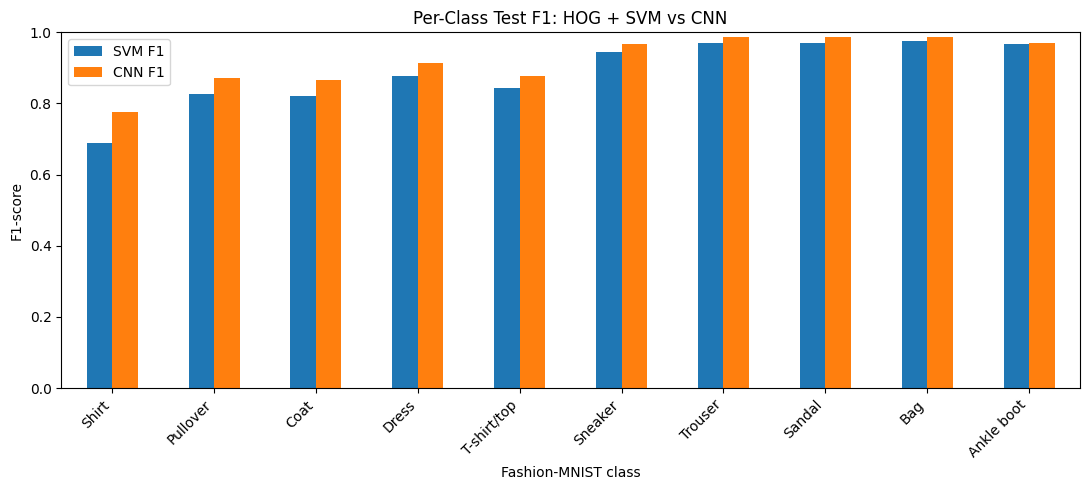

In [31]:
# Present both models' class-specific F1 scores side by side.
class_f1_plot = class_f1_comparison.set_index("Class")[
    ["SVM F1", "CNN F1"]
]

class_f1_plot.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.ylabel("F1-score")
plt.xlabel("Fashion-MNIST class")
plt.title("Per-Class Test F1: HOG + SVM vs CNN")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()

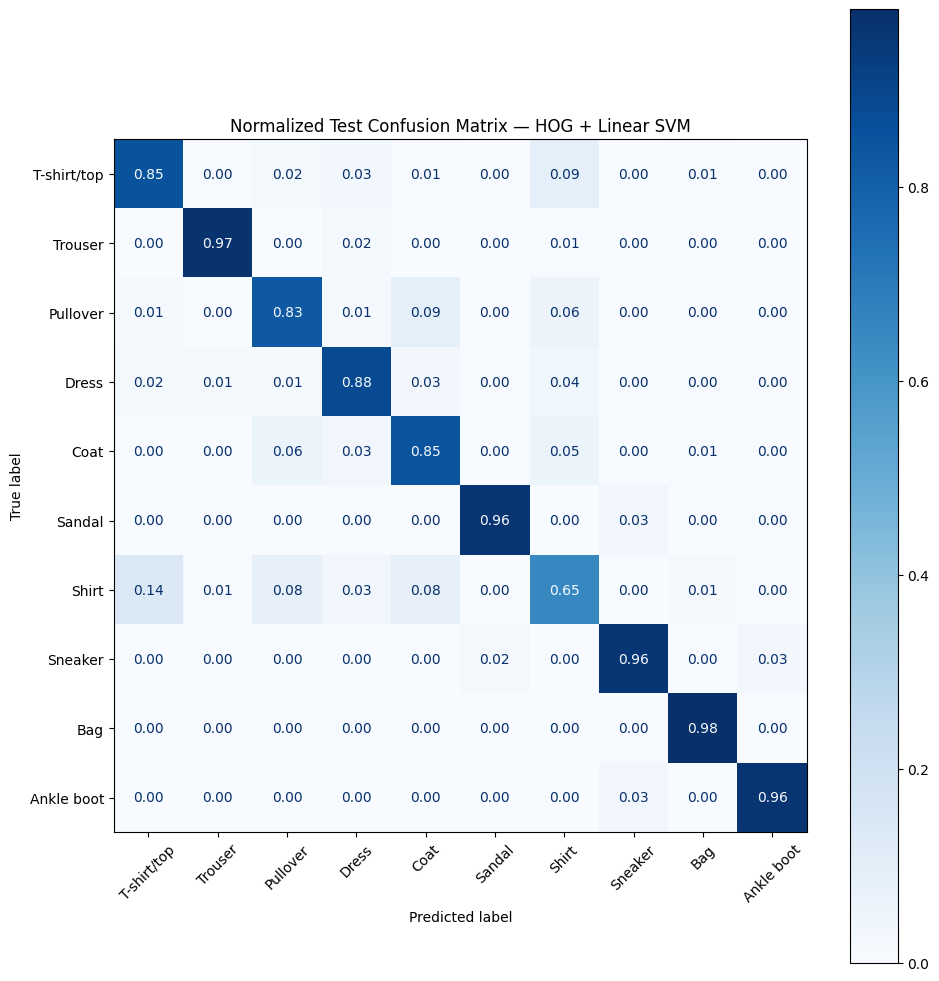

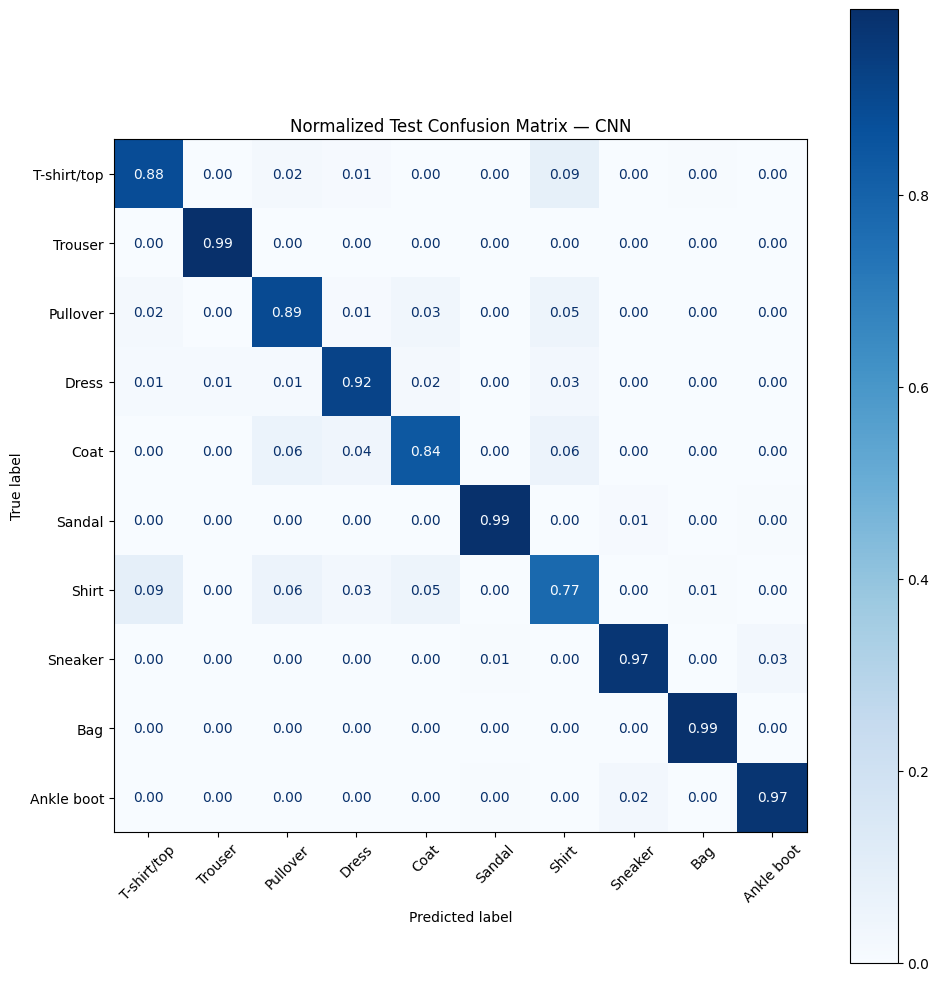

In [32]:
svm_test_cm = confusion_matrix(
    y_test,
    svm_test_pred,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=svm_test_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f"
)

plt.title(
    "Normalized Test Confusion Matrix — HOG + Linear SVM"
)

plt.tight_layout()
plt.show()

cnn_test_cm = confusion_matrix(
    cnn_test_true,
    cnn_test_pred,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_test_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f"
)

plt.title(
    "Normalized Test Confusion Matrix — CNN"
)

plt.tight_layout()
plt.show()


In [33]:
# Find the lowest-F1 class for each final model.
svm_worst_class = (
    svm_test_class_metrics["f1-score"].idxmin()
)

cnn_worst_class = (
    cnn_test_class_metrics["f1-score"].idxmin()
)

print(
    "SVM hardest class:",
    svm_worst_class,
    f"({svm_test_class_metrics.loc[svm_worst_class, 'f1-score']:.4f})"
)

print(
    "CNN hardest class:",
    cnn_worst_class,
    f"({cnn_test_class_metrics.loc[cnn_worst_class, 'f1-score']:.4f})"
)

SVM hardest class: Shirt (0.6895)
CNN hardest class: Shirt (0.7775)


The CNN outperforms HOG + SVM for every class in the final test set. Its largest F1 gains occur for Shirt, Coat and Pullover. This supports the interpretation that learned convolutional representations capture distinctions not fully expressed by fixed HOG features.

However, Shirt remains the weakest class for both models: F1 = 0.6895 for HOG + SVM and 0.7775 for the CNN. The remaining difficulty is consistent with genuine visual similarity among Shirt, T-shirt/top, Pullover and Coat at 28×28 resolution.



7. Explainable AI

Two complementary local explanation methods are used:
- LIME for HOG + SVM. LIME perturbs local image regions and fits an interpretable surrogate around one prediction (Ribeiro, Singh and Guestrin, 2016).
- Integrated Gradients for the CNN. It attributes the selected class score back to input pixels by accumulating gradients along a path from a baseline input to the observed input (Sundararajan, Taly and Yan, 2017).

These methods provide local explanations, not causal proofs or complete descriptions of global model behaviour.
For the LinearSVC wrapper, decision-function scores are passed through Softmax only to provide LIME with probability-like normalised values. They are not treated as calibrated probabilities.

In [34]:
def svm_lime_predict(images):
    """
    Prediction wrapper allowing LIME to explain the final HOG + SVM model.

    LIME supplies perturbed RGB images. Each image is converted back to
    grayscale, transformed using the same HOG settings as the final model,
    and passed through the frozen LinearSVC.

    Returns
    -------
    np.ndarray
        Normalised class scores for each perturbed image.
    """

    hog_feature_batch = []

    for image_rgb in images:

        # LIME represents the image with three channels.
        # Fashion-MNIST is grayscale, so convert it back to one channel.
        image_gray = image_rgb.mean(axis=2).astype(np.float32)

        # Apply exactly the same HOG representation used to train the SVM.
        features = hog(
            image_gray,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        hog_feature_batch.append(features)

    hog_feature_batch = np.array(hog_feature_batch)

    # LinearSVC returns decision scores rather than probabilities.
    decision_scores = final_svm.decision_function(
        hog_feature_batch
    )

    # LIME expects probability-like values. Softmax converts the decision
    # scores into normalised values that sum to one for each image.
    lime_scores = softmax(
        decision_scores,
        axis=1
    )

    return lime_scores

shirt_class = class_names.index("Shirt")

print(shirt_class)

def lime_segmentation(image):
    """
    Divide the tiny Fashion-MNIST image into a manageable number
    of local regions for LIME perturbation.
    """

    return slic(
        image,
        n_segments=25,
        compactness=10,
        sigma=1,
        start_label=0
    )

# Reproducible LIME explainer.
lime_explainer = lime_image.LimeImageExplainer(random_state=123)


6


Shirts misclassified by SVM but correctly classified by CNN: 181
True class: Shirt
SVM prediction: Coat
CNN prediction: Shirt


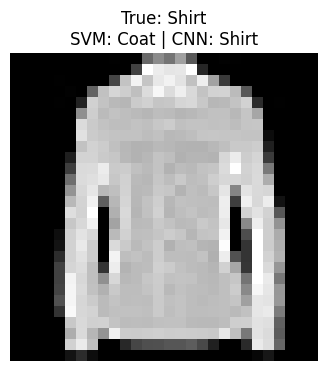

In [35]:
# Find Shirt images where:
# - the true class is Shirt,
# - HOG + SVM predicts the wrong class,
# - CNN predicts Shirt correctly.
svm_wrong_cnn_right_shirts = np.where(
    (y_test == shirt_class)
    & (svm_test_pred != shirt_class)
    & (cnn_test_pred == shirt_class)
)[0]

print(
    "Shirts misclassified by SVM but correctly classified by CNN:",
    len(svm_wrong_cnn_right_shirts)
)

# Select one difficult example for comparative explainability analysis.
comparison_index = svm_wrong_cnn_right_shirts[0]

true_label = y_test[comparison_index]
svm_prediction = svm_test_pred[comparison_index]
cnn_prediction = cnn_test_pred[comparison_index]

print("True class:", class_names[true_label])
print("SVM prediction:", class_names[svm_prediction])
print("CNN prediction:", class_names[cnn_prediction])

plt.figure(figsize=(4, 4))

plt.imshow(
    X_test_images[comparison_index],
    cmap="gray"
)

plt.title(
    f"True: {class_names[true_label]}\n"
    f"SVM: {class_names[svm_prediction]} | "
    f"CNN: {class_names[cnn_prediction]}"
)

plt.axis("off")
plt.show()


  0%|          | 0/1000 [00:00<?, ?it/s]

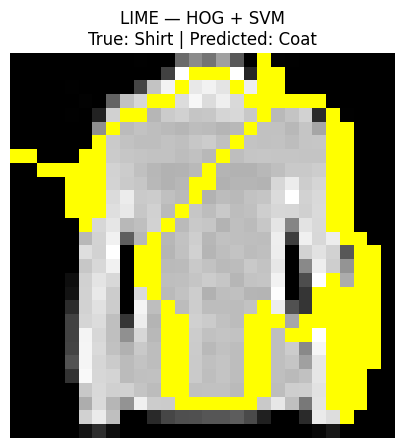

In [36]:
# LIME's image interface expects three channels.
# Repeating the grayscale channel does not add new information.
lime_comparison_image = np.stack(
    [
        X_test_images[comparison_index],
        X_test_images[comparison_index],
        X_test_images[comparison_index]
    ],
    axis=-1
)

# Explain the SVM's behaviour on the selected difficult image.
svm_comparison_explanation = lime_explainer.explain_instance(
    lime_comparison_image,
    classifier_fn=svm_lime_predict,
    top_labels=10,
    hide_color=0,
    num_samples=1000,
    segmentation_fn=lime_segmentation
)

svm_wrong_class = svm_test_pred[comparison_index]

lime_wrong_image, lime_wrong_mask = (
    svm_comparison_explanation.get_image_and_mask(
        label=svm_wrong_class,
        positive_only=True,
        num_features=5,
        hide_rest=False
    )
)

plt.figure(figsize=(5, 5))

plt.imshow(
    mark_boundaries(
        lime_wrong_image,
        lime_wrong_mask
    )
)

plt.title(
    "LIME — HOG + SVM\n"
    f"True: Shirt | Predicted: {class_names[svm_wrong_class]}"
)

plt.axis("off")
plt.show()


The selected example is deliberately diagnostic: the true class is Shirt, HOG + SVM makes an incorrect prediction, and the CNN classifies it correctly. LIME highlights local regions that most strongly support the SVM's predicted class under its perturbation-based surrogate. The explanation should therefore be interpreted as evidence about this individual prediction rather than a global rule.

7.1 CNN explanation with Integrated Gradients

The same difficult class is examined with the final CNN. A zero tensor is used as the baseline in normalised input space, which corresponds approximately to the training-set mean intensity.

A correct Shirt prediction and a misclassified Shirt are both visualised so explanation is used for diagnosis rather than only for demonstrating a successful prediction.

CNN-misclassified Shirts: 226
True: Shirt
CNN predicted: Pullover


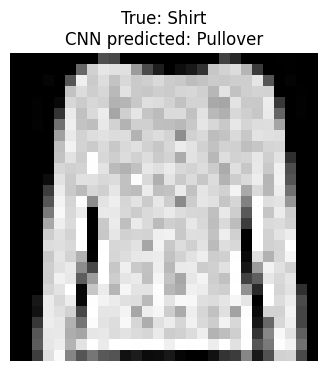

In [37]:
# Find Shirts that the final CNN misclassified.
cnn_wrong_shirts = np.where(
    (y_test == shirt_class)
    & (cnn_test_pred != shirt_class)
)[0]

print(
    "CNN-misclassified Shirts:",
    len(cnn_wrong_shirts)
)

cnn_wrong_index = cnn_wrong_shirts[0]

cnn_wrong_prediction = cnn_test_pred[
    cnn_wrong_index
]

print(
    "True:",
    class_names[y_test[cnn_wrong_index]]
)

print(
    "CNN predicted:",
    class_names[cnn_wrong_prediction]
)

plt.figure(figsize=(4, 4))

plt.imshow(
    X_test_images[cnn_wrong_index],
    cmap="gray"
)

plt.title(
    f"True: Shirt\n"
    f"CNN predicted: {class_names[cnn_wrong_prediction]}"
)

plt.axis("off")
plt.show()


True: Shirt
Predicted: Shirt
Convergence delta: -0.00518798828125
IG min: -0.49975333
IG max: 0.6597446
IG std: 0.11141127


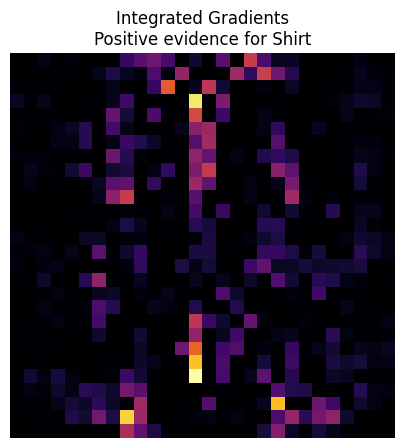

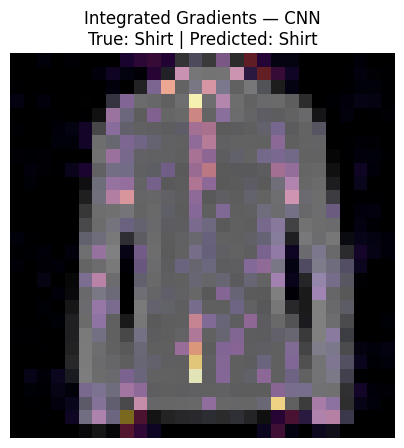

In [38]:
final_cnn.eval()
# Integrated Gradients attributes the CNN prediction back to
# individual input pixels.
integrated_gradients = IntegratedGradients(
    final_cnn
)

cnn_image_tensor, true_label = final_test_dataset[
    comparison_index
]

cnn_image_batch = (
    cnn_image_tensor
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():
    output = final_cnn(cnn_image_batch)

predicted_class = output.argmax(dim=1).item()

print("True:", class_names[true_label])
print("Predicted:", class_names[predicted_class])

# Zero in normalised input space corresponds approximately
# to the mean training-image intensity.
baseline = torch.zeros_like(
    cnn_image_batch
)

# Attribute the CNN's predicted class back to the input pixels.
ig_attributions, convergence_delta = (
    integrated_gradients.attribute(
        cnn_image_batch,
        baselines=baseline,
        target=predicted_class,
        n_steps=64,
        return_convergence_delta=True
    )
)

print(
    "Convergence delta:",
    convergence_delta.item()
)

ig_map = (
    ig_attributions
    .squeeze()
    .detach()
    .cpu()
    .numpy()
)

print("IG min:", ig_map.min())
print("IG max:", ig_map.max())
print("IG std:", ig_map.std())

# Keep positive contributions to the predicted class.
ig_positive = np.maximum(
    ig_map,
    0
)

# Scale to 0–1 only for visualisation.
if ig_positive.max() > ig_positive.min():
    ig_positive = (
        ig_positive - ig_positive.min()
    ) / (
        ig_positive.max()
        - ig_positive.min()
    )

plt.figure(figsize=(5, 5))

plt.imshow(
    ig_positive,
    cmap="inferno"
)

plt.title(
    "Integrated Gradients\n"
    f"Positive evidence for {class_names[predicted_class]}"
)

plt.axis("off")
plt.show()

plt.figure(figsize=(5, 5))

plt.imshow(
    X_test_images[comparison_index],
    cmap="gray"
)

plt.imshow(
    ig_positive,
    cmap="inferno",
    alpha=0.5
)

plt.title(
    "Integrated Gradients — CNN\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_class]}"
)

plt.axis("off")
plt.show()


True class: Shirt
CNN prediction: Pullover


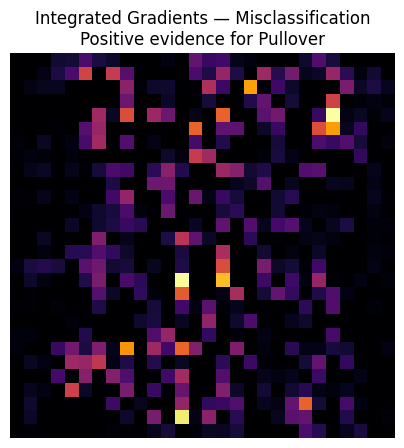

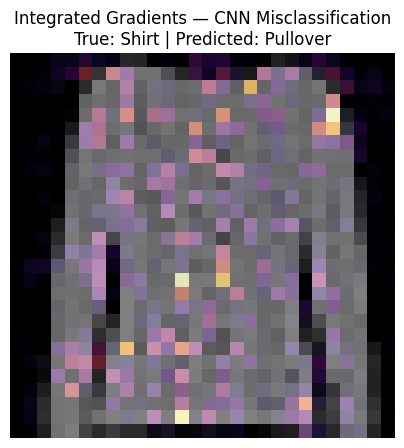

In [39]:
wrong_cnn_tensor, wrong_true_label = (
    final_test_dataset[cnn_wrong_index]
)

wrong_cnn_batch = (
    wrong_cnn_tensor
    .unsqueeze(0)
    .to(device)
)

with torch.no_grad():
    wrong_output = final_cnn(
        wrong_cnn_batch
    )

wrong_predicted_class = (
    wrong_output.argmax(dim=1).item()
)

wrong_baseline = torch.zeros_like(
    wrong_cnn_batch
)

wrong_ig, wrong_delta = (
    integrated_gradients.attribute(
        wrong_cnn_batch,
        baselines=wrong_baseline,
        target=wrong_predicted_class,
        n_steps=64,
        return_convergence_delta=True
    )
)

wrong_ig_map = (
    wrong_ig
    .squeeze()
    .detach()
    .cpu()
    .numpy()
)

# Keep only pixels that positively support the CNN's
# incorrect predicted class.
wrong_ig_positive = np.maximum(
    wrong_ig_map,
    0
)

# Normalise the attribution values to 0–1 for visualisation.
if wrong_ig_positive.max() > wrong_ig_positive.min():
    wrong_ig_positive = (
        wrong_ig_positive
        - wrong_ig_positive.min()
    ) / (
        wrong_ig_positive.max()
        - wrong_ig_positive.min()
    )

print(
    "True class:",
    class_names[wrong_true_label]
)

print(
    "CNN prediction:",
    class_names[wrong_predicted_class]
)

plt.figure(figsize=(5, 5))

plt.imshow(
    wrong_ig_positive,
    cmap="inferno"
)

plt.title(
    "Integrated Gradients — Misclassification\n"
    f"Positive evidence for "
    f"{class_names[wrong_predicted_class]}"
)

plt.axis("off")
plt.show()

plt.figure(figsize=(5, 5))

# Original Fashion-MNIST image.
plt.imshow(
    X_test_images[cnn_wrong_index],
    cmap="gray"
)

# Integrated Gradients attribution.
plt.imshow(
    wrong_ig_positive,
    cmap="inferno",
    alpha=0.5
)

plt.title(
    "Integrated Gradients — CNN Misclassification\n"
    f"True: {class_names[wrong_true_label]} | "
    f"Predicted: {class_names[wrong_predicted_class]}"
)

plt.axis("off")
plt.show()


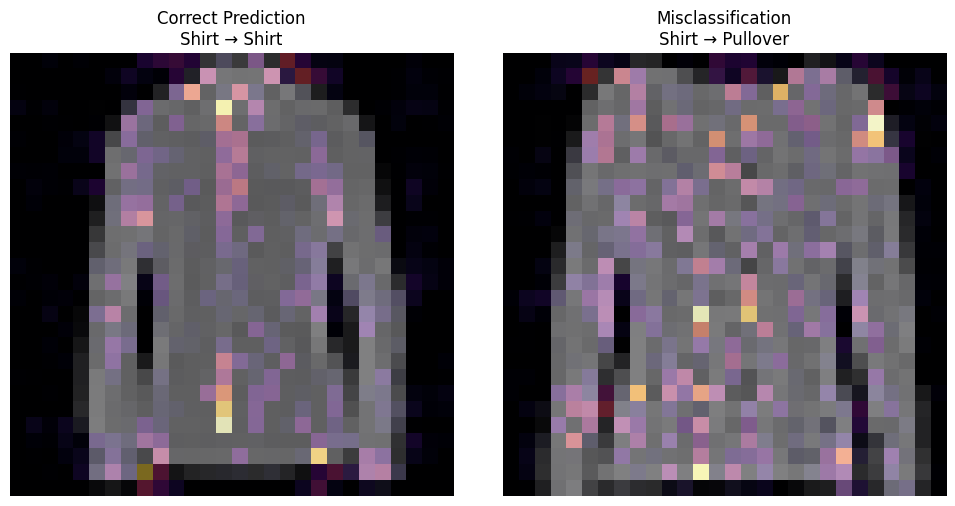

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Correct Shirt prediction.
axes[0].imshow(
    X_test_images[comparison_index],
    cmap="gray"
)

axes[0].imshow(
    ig_positive,
    cmap="inferno",
    alpha=0.5
)

axes[0].set_title(
    "Correct Prediction\n"
    f"Shirt → Shirt"
)

axes[0].axis("off")

# Incorrect Shirt prediction.
axes[1].imshow(
    X_test_images[cnn_wrong_index],
    cmap="gray"
)

axes[1].imshow(
    wrong_ig_positive,
    cmap="inferno",
    alpha=0.5
)

axes[1].set_title(
    "Misclassification\n"
    f"Shirt → {class_names[wrong_predicted_class]}"
)

axes[1].axis("off")

plt.tight_layout()
plt.show()

For the misclassified Shirt, Integrated Gradients places positive attribution around regions of the garment that resemble a T-shirt/top, particularly the upper-body silhouette. This is consistent with the confusion-matrix result that these neighbouring categories remain difficult.

Methodological note on Grad-CAM

Grad-CAM (Selvaraju et al., 2017) was initially tested at the final convolutional layer. For the selected examples, the class-weighted activation map was entirely negative; the standard positive Grad-CAM ReLU therefore collapsed the visualisation to zero. Rather than applying an absolute-value transformation that would change the method's interpretation, Integrated Gradients was retained as the CNN XAI method. This illustrates an important limitation of XAI: an explanation method can itself be unsuitable or uninformative for a particular architecture/example.

8. Bias, diagnostic and robustness analysis

Fashion-MNIST contains no demographic attributes, so demographic fairness cannot be assessed. The diagnostic analysis therefore focuses on two forms of disparity that the data can support:

1. class-level disparity, already demonstrated by Shirt versus easier classes;

2. image-condition disparity, using controlled changes in brightness, contrast and noise.

The same final test observations are transformed while labels remain unchanged. These perturbations simulate plausible distribution shifts in image quality. They are diagnostic tests only; they are not used for retraining.

In [41]:
# Reduce overall intensity to simulate poorer illumination.
X_test_dark = np.clip(
    X_test_images * 0.5,
    0,
    1
)

# Reduce contrast by moving pixel values toward the
# mean intensity of each individual image.
image_means = X_test_images.mean(
    axis=(1, 2),
    keepdims=True
)

X_test_low_contrast = np.clip(
    image_means
    + 0.5 * (
        X_test_images - image_means
    ),
    0,
    1
)

# Use a fixed seed so the same noisy test set is produced
# every time the notebook runs.
rng = np.random.default_rng(123)

noise = rng.normal(
    loc=0.0,
    scale=0.15,
    size=X_test_images.shape
)

X_test_noisy = np.clip(
    X_test_images + noise,
    0,
    1
)

# Group all image-quality conditions for consistent evaluation.
conditions = [
    ("Original", X_test_images),
    ("Dark", X_test_dark),
    ("Low contrast", X_test_low_contrast),
    ("Noisy", X_test_noisy)
]


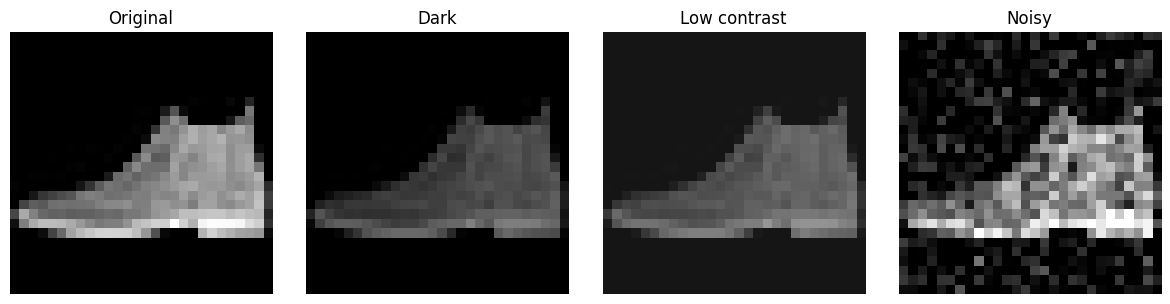

In [42]:
# Use the same display scale for every condition so brightness
# and contrast changes are visually represented fairly.
sample_index = 0

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for ax, (name, dataset) in zip(axes, conditions):
    ax.imshow(
        dataset[sample_index],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
def evaluate_svm_condition(
    images,
    labels,
    model
):
    """
    Evaluate the final HOG + SVM model on a modified
    version of the test images.
    """

    hog_features = extract_hog_features(
        images
    )

    predictions = model.predict(
        hog_features
    )

    return {
        "Accuracy": accuracy_score(
            labels,
            predictions
        ),
        "Precision": precision_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    }

svm_robustness_results = {}

for condition_name, images in conditions:

    print(
        f"Evaluating SVM: {condition_name}"
    )

    svm_robustness_results[
        condition_name
    ] = evaluate_svm_condition(
        images,
        y_test,
        final_svm
    )

svm_robustness_df = pd.DataFrame(
    svm_robustness_results
).T

svm_robustness_df


Evaluating SVM: Original
Evaluating SVM: Dark
Evaluating SVM: Low contrast
Evaluating SVM: Noisy


,Accuracy,Precision,Recall,F1
Original,0.8894,0.888462,0.8894,0.888616
Dark,0.8894,0.888462,0.8894,0.888616
Low contrast,0.8894,0.888462,0.8894,0.888616
Noisy,0.3514,0.748186,0.3514,0.304534


In [44]:
def predict_cnn_from_numpy(
    images,
    model,
    device,
    mean,
    std,
    batch_size=64
):
    """
    Predict classes for NumPy images using the final CNN.

    The same training-derived normalisation is applied to
    every image condition.
    """

    model.eval()

    all_predictions = []

    for start in range(
        0,
        len(images),
        batch_size
    ):

        batch = images[
            start:start + batch_size
        ]

        # Shape:
        # [batch, 28, 28]
        #        ↓
        # [batch, 1, 28, 28]
        batch_tensor = torch.tensor(
            batch,
            dtype=torch.float32
        ).unsqueeze(1)

        # Apply the exact same normalisation used during training.
        batch_tensor = (
            batch_tensor - mean
        ) / std

        batch_tensor = batch_tensor.to(
            device
        )

        with torch.no_grad():
            outputs = model(
                batch_tensor
            )

            predictions = outputs.argmax(
                dim=1
            )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

    return np.array(
        all_predictions
    )

cnn_robustness_results = {}

for condition_name, images in conditions:

    print(
        f"Evaluating CNN: {condition_name}"
    )

    predictions = predict_cnn_from_numpy(
        images=images,
        model=final_cnn,
        device=device,
        mean=final_mean,
        std=final_std
    )

    cnn_robustness_results[
        condition_name
    ] = {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),
        "F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    }

cnn_robustness_df = pd.DataFrame(
    cnn_robustness_results
).T

cnn_robustness_df


Evaluating CNN: Original
Evaluating CNN: Dark
Evaluating CNN: Low contrast
Evaluating CNN: Noisy


,Accuracy,Precision,Recall,F1
Original,0.9205,0.920410,0.9205,0.920346
Dark,0.8746,0.886784,0.8746,0.870555
Low contrast,0.8801,0.884456,0.8801,0.878191
Noisy,0.7888,0.850141,0.7888,0.787249


,Condition,SVM F1,CNN F1
0,Original,0.888616,0.920346
1,Dark,0.888616,0.870555
2,Low contrast,0.888616,0.878191
3,Noisy,0.304534,0.787249


,Condition,SVM F1,CNN F1,SVM F1 Drop,CNN F1 Drop
0,Original,0.888616,0.920346,0.000000,0.000000
1,Dark,0.888616,0.870555,0.000000,0.049791
2,Low contrast,0.888616,0.878191,0.000000,0.042155
3,Noisy,0.304534,0.787249,0.584082,0.133097


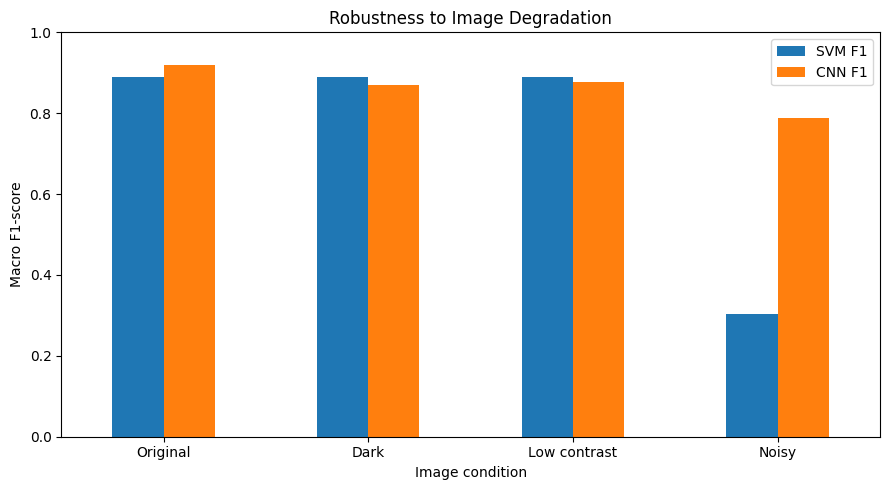

In [45]:
robustness_comparison = pd.DataFrame({
    "Condition": [
        name
        for name, _ in conditions
    ],

    "SVM F1": [
        svm_robustness_df.loc[
            name,
            "F1"
        ]
        for name, _ in conditions
    ],

    "CNN F1": [
        cnn_robustness_df.loc[
            name,
            "F1"
        ]
        for name, _ in conditions
    ]
})

display(robustness_comparison)

svm_original_f1 = robustness_comparison.loc[
    robustness_comparison["Condition"] == "Original",
    "SVM F1"
].iloc[0]

cnn_original_f1 = robustness_comparison.loc[
    robustness_comparison["Condition"] == "Original",
    "CNN F1"
].iloc[0]

robustness_comparison[
    "SVM F1 Drop"
] = (
    svm_original_f1
    - robustness_comparison["SVM F1"]
)

robustness_comparison[
    "CNN F1 Drop"
] = (
    cnn_original_f1
    - robustness_comparison["CNN F1"]
)

display(robustness_comparison)

robustness_comparison.set_index(
    "Condition"
)[
    ["SVM F1", "CNN F1"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.ylabel("Macro F1-score")
plt.xlabel("Image condition")
plt.title(
    "Robustness to Image Degradation"
)

plt.xticks(
    rotation=0
)

plt.ylim(
    0,
    1
)

plt.tight_layout()
plt.show()


,Noise Std,SVM F1,CNN F1
0,0.05,0.700337,0.901477
1,0.10,0.463819,0.858231
2,0.15,0.309845,0.789431


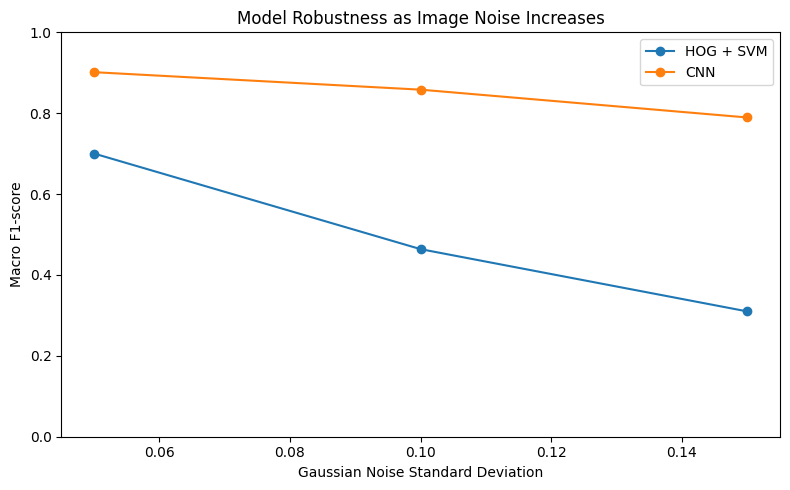

In [46]:
noise_levels = [0.05, 0.10, 0.15]

noise_results = []

# Use the same fixed seed for reproducibility.
rng = np.random.default_rng(123)

for noise_level in noise_levels:

    noise = rng.normal(
        loc=0.0,
        scale=noise_level,
        size=X_test_images.shape
    )

    noisy_images = np.clip(
        X_test_images + noise,
        0,
        1
    )

    # -------------------------
    # HOG + SVM
    # -------------------------
    svm_result = evaluate_svm_condition(
        noisy_images,
        y_test,
        final_svm
    )

    # -------------------------
    # CNN
    # -------------------------
    cnn_predictions = predict_cnn_from_numpy(
        images=noisy_images,
        model=final_cnn,
        device=device,
        mean=final_mean,
        std=final_std
    )

    cnn_f1_noise = f1_score(
        y_test,
        cnn_predictions,
        average="macro",
        zero_division=0
    )

    noise_results.append({
        "Noise Std": noise_level,
        "SVM F1": svm_result["F1"],
        "CNN F1": cnn_f1_noise
    })

noise_results_df = pd.DataFrame(
    noise_results
)

display(noise_results_df)

plt.figure(figsize=(8, 5))

plt.plot(
    noise_results_df["Noise Std"],
    noise_results_df["SVM F1"],
    marker="o",
    label="HOG + SVM"
)

plt.plot(
    noise_results_df["Noise Std"],
    noise_results_df["CNN F1"],
    marker="o",
    label="CNN"
)

plt.xlabel("Gaussian Noise Standard Deviation")
plt.ylabel("Macro F1-score")
plt.title("Model Robustness as Image Noise Increases")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.show()


Robustness findings

The models have complementary robustness profiles:
- HOG + SVM is effectively invariant to these global brightness/contrast scalings. Multiplying image intensity scales gradient magnitudes but largely preserves orientations, and L2-Hys block normalisation suppresses uniform magnitude changes.
- Gaussian noise creates many artificial local gradients, strongly corrupting the HOG descriptor. Its F1 falls from 0.8886 to 0.3045 at σ=0.15.
- The CNN is more sensitive to brightness/contrast distribution shift because it consumes normalised pixel intensities learned from the original training distribution.
- The CNN is substantially more robust to Gaussian noise, retaining F1 = 0.789431 at σ=0.15.

The multi-level noise test confirms progressive degradation: at σ = 0.05, 0.10 and 0.15, HOG + SVM F1 falls to approximately 0.700, 0.464 and 0.310, while CNN F1 remains approximately 0.901, 0.858 and 0.789431.

Therefore robustness is shift-dependent; clean-data accuracy alone is not sufficient to characterise deployment risk.

9. Ethical considerations

9.1 Privacy and data provenance

Fashion-MNIST itself presents relatively low direct privacy risk because it contains product-style clothing images rather than identifiable people. That characteristic does not automatically transfer to deployment. A real marketplace may receive seller or customer photographs containing faces, private surroundings or associated metadata. A production system would therefore require clear retention rules, access controls and an appropriate lawful basis for processing images.

9.2 Algorithmic fairness and performance disparity

The benchmark has no demographic variables, so claims about demographic fairness would be unsupported. The measurable disparity is instead between clothing categories and image conditions. Shirt is materially less reliable than Trouser, and model performance changes under degraded image quality.

In a marketplace, unequal error rates can create unequal economic outcomes. Sellers whose products fall into harder categories, or whose images are systematically lower quality, could experience more incorrect catalogue placement and reduced search exposure.

9.3 False positives and false negatives

Using Shirt as an example:
- A false negative occurs when a real Shirt is labelled T-shirt/top, Pullover or another class. It may disappear from Shirt-filtered search and lose relevant exposure.
- A false positive occurs when a non-Shirt is labelled Shirt. This reduces category/search relevance and can frustrate customers.

These errors are primarily commercial and user-experience harms rather than safety-critical harms, but they can still be systematic and consequential.

9.4 Representation bias and limits of the benchmark

Fashion-MNIST is a controlled benchmark, not a representative sample of global fashion. It contains only ten categories, grayscale 28×28 images, standardised viewpoints and simple backgrounds. Real catalogues contain colours, textures, overlapping garments, human models, unusual camera angles, multi-label items, cultural/traditional clothing and new categories.
Accordingly, 92% Fashion-MNIST accuracy must not be interpreted as 92% expected accuracy on real-world fashion photographs. Deployment would require a more representative dataset and a fresh validation process.

9.5 XAI limitations

LIME and Integrated Gradients are useful diagnostic tools, but neither proves causality or makes the model fully transparent. LIME depends on its perturbation/segmentation choices, and Integrated Gradients depends on the chosen baseline. Explanations should therefore supplement quantitative evaluation and human review rather than replace them.

10. Real-world deployment considerations

Recommended model

Based on the experimental evidence, the CNN is the preferred deployment candidate:
- Test Accuracy: 0.9209 vs 0.8894 for HOG + SVM
- Test Macro F1: 0.9204 vs 0.8886
- Largest improvements occur in difficult upper-body classes
- Much stronger robustness to Gaussian noise

The HOG + SVM remains attractive for highly resource-constrained systems and demonstrates excellent invariance to the tested global brightness/contrast scaling, but its severe noise sensitivity is a significant deployment weakness.

Example Architecture

Seller/customer image
  
        ↓

validation + preprocessing

        ↓

CNN inference service (REST API)

        ↓

predicted category + score

        ↓

quality/confidence policy

   ↙                                    ↘

automatic route      human/seller review

        ↓                  ↓

          catalogue/search


The model could be packaged as an API and hosted on a managed platform such as AWS SageMaker, Google Vertex AI or Azure ML.

Scalability and monitoring

A production service should monitor:
- inference latency and service failure rate;
- input/image statistics for data drift;
- predicted class distribution;
- human correction rate and sampled labelled accuracy;
- per-class precision/recall/F1 rather than only overall accuracy;
- image-quality subgroups, because the robustness experiment demonstrated condition-dependent degradation.

Batching and autoscaling can support high request volume. Confidence scores should not automatically be interpreted as calibrated probabilities; calibration should be evaluated before setting an automated review threshold.

Retraining

Retraining should be triggered by meaningful performance degradation, data drift, new clothing categories or accumulation of verified new examples. A replacement model should pass the same validation, subgroup/robustness and ethical checks before deployment.

11. Conclusion

This project compared a classical HOG + Linear SVM pipeline with a compact CNN on the same Fashion-MNIST classification task.

The final evidence supports five main conclusions:

1. Deep learning delivered higher predictive performance. The CNN achieved test Accuracy and Macro F1, approximately 3.2 percentage points above HOG + SVM.

2. Cross-validation estimates transferred well to the held-out test set. The close CV/test results support the generalisation methodology.

3. The CNN's largest gains were on difficult upper-body classes, yet Shirt remained the weakest class for both models, indicating residual ambiguity in the low-resolution data.

4. Robustness was not one-dimensional. HOG + SVM was invariant to the tested global brightness/contrast scaling but highly vulnerable to Gaussian noise; the CNN showed the opposite trade-off.

5. The CNN is the preferred deployment candidate, but not without safeguards. More representative real-world training data, image-quality monitoring, per-class performance monitoring and human review for uncertain cases are necessary before production use.

Limitations and future work

Future work should validate on realistic colour marketplace images, investigate data augmentation for brightness/contrast robustness, evaluate calibrated confidence thresholds, and repeat fairness/robustness analysis on representative real-world subgroups. The current conclusions are specific to Fashion-MNIST and the tested model configurations.